# AttnGAN-Inspired Text-to-Image Synthesis
### University Assignment — Baseline vs Improved Model Comparison

**Dataset:** 200 Bird Species (Kaggle — 11,788 Images)  
**Goal:** Demonstrate how attention-based text conditioning improves GAN image generation  

> **Run Order:** Execute every cell top-to-bottom. Each cell is self-contained with its imports.


---
## SECTION 1 — Design Strategy

### Why Previous Attempts Failed
| Problem | Root Cause | Our Fix |
|---|---|---|
| Corrupted 1 GB upload | Colab RAM limit + unstable upload | Kaggle API direct download |
| No captions in dataset | CUB/bird datasets lack NL captions | Template-based caption generation from class labels |
| Only 15 images | Too small to learn anything | 200 curated images across 10 classes |
| Checkerboard noise | ConvTranspose2d stride artifacts | Upsample + Conv2d in improved model |
| Weak text-image alignment | No attention, only sentence vector | Word-level cross-attention in improved model |
| Discriminator crushes generator | LR imbalance | G_lr = 2×D_lr, label smoothing |
| Training too short | 5 epochs | 60 epochs with checkpoint saves |

### Architecture Summary
- **Baseline:** Simple embedding → Linear → ConvTranspose generator  
- **Improved:** LSTM word encoder → word-level attention → Upsample+Conv generator  


## Cell 1 — Install Dependencies

In [4]:
# Cell 1: Install all required dependencies
# Run once per Colab session

import subprocess, sys

def install(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

install("kaggle")
install("Pillow")
install("matplotlib")
install("numpy")
install("torch")
install("torchvision")
install("tqdm")

print("✅ All dependencies installed.")
print("⚠️  Next step: Upload your kaggle.json API token when prompted in Cell 2.")


✅ All dependencies installed.
⚠️  Next step: Upload your kaggle.json API token when prompted in Cell 2.


## Cell 2 — Kaggle Authentication & Dataset Download

In [8]:
# Cell 2: Authenticate with Kaggle and download the dataset

import os, json, subprocess
from google.colab import files

# ── Step 1: Upload kaggle.json ────────────────────────────────────────────────
print("Upload your kaggle.json file when the picker appears …")
uploaded = files.upload()

raw_bytes = list(uploaded.values())[0]
kaggle_data = json.loads(raw_bytes)

username = kaggle_data.get("username", "")
key      = kaggle_data.get("key", "")
print(f"✅ Detected username: {username}")

# Save to ~/.kaggle/kaggle.json
kaggle_dir  = os.path.expanduser("~/.kaggle")
kaggle_path = os.path.join(kaggle_dir, "kaggle.json")
os.makedirs(kaggle_dir, exist_ok=True)
with open(kaggle_path, "w") as f:
    json.dump({"username": username, "key": key}, f)
os.chmod(kaggle_path, 0o600)
print("✅ kaggle.json saved.")

# ── Step 2: Install kaggle package ───────────────────────────────────────────
subprocess.check_call(["pip", "install", "-q", "kaggle"])

# ── Step 3: Try dataset slugs in order until one works ───────────────────────
os.makedirs("/content/birds_raw", exist_ok=True)

SLUGS = [
    "veeralakrishna/200-bird-species-with-11788-images",
    "gpiosenka/100-bird-species",
    "akash2907/bird-species-classification",
]

success = False
for slug in SLUGS:
    print(f"\n⏳ Trying slug: {slug} …")
    result = subprocess.run(
        ["kaggle", "datasets", "download", "-d", slug,
         "--path", "/content/birds_raw"],
        capture_output=True, text=True
    )
    if result.returncode == 0:
        print(f"✅ Downloaded successfully using slug: {slug}")
        success = True
        break
    else:
        print(f"   ✗ Failed: {result.stderr.strip()[:120]}")

if not success:
    print("""
❌ All slugs failed. Most likely cause: your Kaggle account
   has not accepted the dataset rules yet.

👉 Fix in 30 seconds:
   1. Go to https://www.kaggle.com/datasets/veeralakrishna/200-bird-species-with-11788-images
   2. Click the Download button once — accept any rules popup
   3. Re-run this cell
""")

Upload your kaggle.json file when the picker appears …


Saving kaggle.json to kaggle (2).json
✅ Detected username: rewanhany
✅ kaggle.json saved.

⏳ Trying slug: veeralakrishna/200-bird-species-with-11788-images …
✅ Downloaded successfully using slug: veeralakrishna/200-bird-species-with-11788-images


## Cell 3 — Extract Dataset

In [9]:
# Cell 3: Extract the downloaded zip file

import zipfile, os, glob

RAW_DIR   = "/content/birds_raw"
EXTRACT_DIR = "/content/birds_extracted"

zip_files = glob.glob(os.path.join(RAW_DIR, "*.zip"))
if not zip_files:
    raise FileNotFoundError(f"No zip found in {RAW_DIR}. Did Cell 2 succeed?")

zip_path = zip_files[0]
print(f"Extracting: {zip_path}")

os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(EXTRACT_DIR)

# Show top-level structure
print("\nExtracted structure:")
for item in sorted(os.listdir(EXTRACT_DIR))[:20]:
    print("  ", item)
print("✅ Extraction complete.")


Extracting: /content/birds_raw/200-bird-species-with-11788-images.zip

Extracted structure:
   CUB_200_2011.tgz
   segmentations.tgz
✅ Extraction complete.


## Cell 4 — Create Manageable Subset (200 images, 10 classes)

In [14]:
# Cell 4: Select 200 images from 10 bird species for fast training
# Strategy: 20 images per class × 10 classes = 200 images

import os, shutil, glob, random

IMAGE_ROOT     = "/content/birds_extracted/CUB_200_2011/images"
SUBSET_DIR     = "/content/birds_subset"
IMGS_PER_CLASS = 20
NUM_CLASSES    = 10
SEED           = 42
random.seed(SEED)

os.makedirs(SUBSET_DIR, exist_ok=True)

all_classes = sorted([
    d for d in os.listdir(IMAGE_ROOT)
    if os.path.isdir(os.path.join(IMAGE_ROOT, d))
])
print(f"Total classes available: {len(all_classes)}")

# Pick 10 classes with the most images
class_counts = {}
for cls in all_classes:
    imgs = (glob.glob(os.path.join(IMAGE_ROOT, cls, "*.jpg")) +
            glob.glob(os.path.join(IMAGE_ROOT, cls, "*.jpeg")) +
            glob.glob(os.path.join(IMAGE_ROOT, cls, "*.png")))
    class_counts[cls] = len(imgs)

selected_classes = sorted(class_counts, key=class_counts.get, reverse=True)[:NUM_CLASSES]
print(f"\nSelected {NUM_CLASSES} classes:")

image_paths = []
for cls in selected_classes:
    imgs = (glob.glob(os.path.join(IMAGE_ROOT, cls, "*.jpg")) +
            glob.glob(os.path.join(IMAGE_ROOT, cls, "*.jpeg")) +
            glob.glob(os.path.join(IMAGE_ROOT, cls, "*.png")))
    imgs = random.sample(imgs, min(IMGS_PER_CLASS, len(imgs)))
    cls_dir = os.path.join(SUBSET_DIR, cls)
    os.makedirs(cls_dir, exist_ok=True)
    for src in imgs:
        dst = os.path.join(cls_dir, os.path.basename(src))
        shutil.copy(src, dst)
        image_paths.append((dst, cls))
    print(f"  {cls}: {len(imgs)} images")

print(f"\n✅ Subset created: {len(image_paths)} total images in {SUBSET_DIR}")

Total classes available: 200

Selected 10 classes:
  001.Black_footed_Albatross: 20 images
  002.Laysan_Albatross: 20 images
  004.Groove_billed_Ani: 20 images
  010.Red_winged_Blackbird: 20 images
  011.Rusty_Blackbird: 20 images
  013.Bobolink: 20 images
  014.Indigo_Bunting: 20 images
  021.Eastern_Towhee: 20 images
  025.Pelagic_Cormorant: 20 images
  026.Bronzed_Cowbird: 20 images

✅ Subset created: 200 total images in /content/birds_subset


In [12]:
# Cell 3: Extract the .tgz dataset

import os, tarfile, glob

EXTRACT_DIR = "/content/birds_extracted"
os.makedirs(EXTRACT_DIR, exist_ok=True)

# Find the main tgz (not segmentations)
tgz_files = [f for f in glob.glob(os.path.join(EXTRACT_DIR, "*.tgz"))
             if "segment" not in f.lower()]

if not tgz_files:
    raise FileNotFoundError("No .tgz found. Did Cell 2 succeed?")

tgz_path = tgz_files[0]
print(f"Extracting: {tgz_path} ...")

with tarfile.open(tgz_path, "r:gz") as tar:
    tar.extractall(EXTRACT_DIR)

print("✅ Extraction complete.")
print("\nContents after extraction:")
for item in sorted(os.listdir(EXTRACT_DIR))[:15]:
    full = os.path.join(EXTRACT_DIR, item)
    kind = "DIR" if os.path.isdir(full) else "FILE"
    print(f"  [{kind}] {item}")

Extracting: /content/birds_extracted/CUB_200_2011.tgz ...


/tmp/ipykernel_2680/1310983267.py:19: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(EXTRACT_DIR)


✅ Extraction complete.

Contents after extraction:
  [DIR] CUB_200_2011
  [FILE] CUB_200_2011.tgz
  [FILE] attributes.txt
  [FILE] segmentations.tgz


In [13]:
import os

BASE = "/content/birds_extracted/CUB_200_2011"

print("=== CUB_200_2011 contents ===")
for item in sorted(os.listdir(BASE)):
    full = os.path.join(BASE, item)
    kind = "DIR" if os.path.isdir(full) else "FILE"
    print(f"  [{kind}] {item}")

print("\n=== Inside 'images' folder (first 5 classes) ===")
images_dir = os.path.join(BASE, "images")
if os.path.isdir(images_dir):
    classes = sorted(os.listdir(images_dir))[:5]
    for cls in classes:
        imgs = os.listdir(os.path.join(images_dir, cls))
        print(f"  {cls}/ → {len(imgs)} images, e.g. {imgs[0]}")
else:
    print("  No 'images' folder found!")

=== CUB_200_2011 contents ===
  [FILE] README
  [DIR] attributes
  [FILE] bounding_boxes.txt
  [FILE] classes.txt
  [FILE] image_class_labels.txt
  [DIR] images
  [FILE] images.txt
  [DIR] parts
  [FILE] train_test_split.txt

=== Inside 'images' folder (first 5 classes) ===
  001.Black_footed_Albatross/ → 60 images, e.g. Black_Footed_Albatross_0017_796098.jpg
  002.Laysan_Albatross/ → 60 images, e.g. Laysan_Albatross_0088_883.jpg
  003.Sooty_Albatross/ → 58 images, e.g. Sooty_Albatross_0065_796367.jpg
  004.Groove_billed_Ani/ → 60 images, e.g. Groove_Billed_Ani_0027_1754.jpg
  005.Crested_Auklet/ → 44 images, e.g. Crested_Auklet_0040_794912.jpg


In [11]:
import os

EXTRACT_DIR = "/content/birds_extracted"

print("=== Top-level contents ===")
for item in sorted(os.listdir(EXTRACT_DIR)):
    full = os.path.join(EXTRACT_DIR, item)
    kind = "DIR" if os.path.isdir(full) else "FILE"
    print(f"  [{kind}] {item}")

print("\n=== Going one level deeper ===")
for item in sorted(os.listdir(EXTRACT_DIR)):
    full = os.path.join(EXTRACT_DIR, item)
    if os.path.isdir(full):
        sub = os.listdir(full)
        print(f"  {item}/ → {len(sub)} items, first 5: {sorted(sub)[:5]}")

=== Top-level contents ===
  [FILE] CUB_200_2011.tgz
  [FILE] segmentations.tgz

=== Going one level deeper ===


## Cell 5 — Generate Rich Visual Captions from Class Labels

In [15]:
# Cell 5: Generate descriptive captions using class name + visual templates
# This solves the "no captions in bird datasets" problem with realistic variety

import os, glob, json, random, re

SUBSET_DIR   = "/content/birds_subset"
CAPTION_FILE = "/content/captions.json"
SEED = 42
random.seed(SEED)

# ── Visual property banks (randomised per image) ──────────────────────────────
COLORS     = ["blue", "red", "yellow", "brown", "black", "white",
              "orange", "grey", "green", "purple"]
PATTERNS   = ["spotted", "striped", "plain", "iridescent",
              "speckled", "barred", "mottled"]
SIZES      = ["small", "medium-sized", "large"]
PERCHES    = ["perched on a branch", "sitting on a rock",
              "standing on the ground", "perched on a fence post",
              "resting on a leaf", "perched near water"]
BACKGROUNDS = ["in a forest", "against a clear sky",
               "in a green meadow", "near a river",
               "in dense foliage", "in an open field"]
BEAK_TYPES  = ["short curved beak", "long slender beak",
               "broad flat bill", "sharp pointed beak", "hooked beak"]

TEMPLATES = [
    "A {size} {color} {species} with {pattern} feathers {perch} {background}.",
    "A {species} bird, {size} and {color}, with {pattern} wings {perch} {background}.",
    "This {color} {species} has {pattern} plumage and a {beak}; it is {perch} {background}.",
    "A beautiful {color} and {color2} {species} {perch}, showing its {pattern} feathers {background}.",
    "The {species} is a {size} bird with {color} {pattern} feathers, seen {perch} {background}.",
]

def clean_class_name(cls):
    """Turn 'ACADIAN FLYCATCHER' → 'Acadian Flycatcher'"""
    cls = re.sub(r"[_\-]+", " ", cls)
    # Remove leading numbers like '001 ' sometimes present
    cls = re.sub(r"^\d+\.?\s*", "", cls)
    return cls.title()

def make_caption(species_raw):
    species = clean_class_name(species_raw)
    tpl = random.choice(TEMPLATES)
    color  = random.choice(COLORS)
    color2 = random.choice([c for c in COLORS if c != color])
    return tpl.format(
        size    = random.choice(SIZES),
        color   = color,
        color2  = color2,
        species = species,
        pattern = random.choice(PATTERNS),
        perch   = random.choice(PERCHES),
        background = random.choice(BACKGROUNDS),
        beak    = random.choice(BEAK_TYPES),
    )

# ── Build caption dict {image_path: [cap1, cap2, cap3]} ──────────────────────
caption_dict = {}
all_classes = sorted(os.listdir(SUBSET_DIR))

for cls in all_classes:
    cls_dir = os.path.join(SUBSET_DIR, cls)
    if not os.path.isdir(cls_dir):
        continue
    imgs = glob.glob(os.path.join(cls_dir, "*.jpg")) +            glob.glob(os.path.join(cls_dir, "*.jpeg")) +            glob.glob(os.path.join(cls_dir, "*.png"))
    for img_path in imgs:
        # Generate 3 diverse captions per image
        captions = [make_caption(cls) for _ in range(3)]
        caption_dict[img_path] = captions

with open(CAPTION_FILE, "w") as f:
    json.dump(caption_dict, f, indent=2)

# ── Print samples ─────────────────────────────────────────────────────────────
print(f"✅ Captions generated for {len(caption_dict)} images → {CAPTION_FILE}\n")
print("=== SAMPLE CAPTIONS ===")
for path, caps in list(caption_dict.items())[:3]:
    print(f"\nImage: {os.path.basename(path)}")
    for i, c in enumerate(caps, 1):
        print(f"  [{i}] {c}")


✅ Captions generated for 200 images → /content/captions.json

=== SAMPLE CAPTIONS ===

Image: Black_Footed_Albatross_0050_796125.jpg
  [1] A small blue Black Footed Albatross with striped feathers sitting on a rock in an open field.
  [2] The Black Footed Albatross is a small bird with red spotted feathers, seen perched on a branch against a clear sky.
  [3] The Black Footed Albatross is a large bird with purple striped feathers, seen perched near water in an open field.

Image: Black_Footed_Albatross_0086_796062.jpg
  [1] A beautiful brown and green Black Footed Albatross perched on a branch, showing its plain feathers against a clear sky.
  [2] This black Black Footed Albatross has mottled plumage and a short curved beak; it is standing on the ground in a forest.
  [3] A beautiful red and orange Black Footed Albatross standing on the ground, showing its speckled feathers in a forest.

Image: Black_Footed_Albatross_0006_796065.jpg
  [1] The Black Footed Albatross is a small bird with 

## Cell 6 — Build Vocabulary

In [16]:
# Cell 6: Tokenise captions and build word-to-index vocabulary

import json, re
from collections import Counter

CAPTION_FILE = "/content/captions.json"
VOCAB_FILE   = "/content/vocab.json"

with open(CAPTION_FILE) as f:
    caption_dict = json.load(f)

def tokenise(text):
    return re.findall(r"[a-z]+", text.lower())

counter = Counter()
for caps in caption_dict.values():
    for cap in caps:
        counter.update(tokenise(cap))

# Keep words that appear at least twice
MIN_FREQ = 2
vocab_words = [w for w, c in counter.items() if c >= MIN_FREQ]
vocab_words = sorted(vocab_words)

# Special tokens
special = ["<PAD>", "<UNK>", "<SOS>", "<EOS>"]
word2idx = {tok: i for i, tok in enumerate(special)}
for word in vocab_words:
    word2idx[word] = len(word2idx)
idx2word = {v: k for k, v in word2idx.items()}

vocab_data = {
    "word2idx": word2idx,
    "idx2word": {str(k): v for k, v in idx2word.items()},
    "vocab_size": len(word2idx),
}
with open(VOCAB_FILE, "w") as f:
    json.dump(vocab_data, f, indent=2)

print(f"✅ Vocabulary built: {len(word2idx)} tokens")
print(f"   Sample tokens: {list(word2idx.keys())[:20]}")


✅ Vocabulary built: 95 tokens
   Sample tokens: ['<PAD>', '<UNK>', '<SOS>', '<EOS>', 'a', 'against', 'albatross', 'an', 'and', 'ani', 'barred', 'beak', 'beautiful', 'bill', 'billed', 'bird', 'black', 'blackbird', 'blue', 'bobolink']


## Cell 7 — Dataset Class

In [17]:
# Cell 7: PyTorch Dataset — loads image + random caption

import os, json, re, random
import torch
from torch.utils.data import Dataset
from torchvision import transforms
from PIL import Image

CAPTION_FILE = "/content/captions.json"
VOCAB_FILE   = "/content/vocab.json"
IMG_SIZE     = 64   # 64×64 for fast training in Colab
MAX_SEQ_LEN  = 20

class BirdDataset(Dataset):
    def __init__(self, caption_file, vocab_file, img_size=IMG_SIZE,
                 max_seq_len=MAX_SEQ_LEN):
        with open(caption_file) as f:
            self.captions = json.load(f)
        with open(vocab_file) as f:
            vdata = json.load(f)

        self.word2idx   = vdata["word2idx"]
        self.max_seq_len = max_seq_len
        self.items = [(k, v) for k, v in self.captions.items()
                      if os.path.exists(k)]

        self.transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.RandomHorizontalFlip(),
            transforms.ColorJitter(brightness=0.1, saturation=0.1),
            transforms.ToTensor(),
            transforms.Normalize([0.5]*3, [0.5]*3),
        ])

    def __len__(self):
        return len(self.items)

    def tokenise(self, text):
        words = re.findall(r"[a-z]+", text.lower())
        sos   = self.word2idx.get("<SOS>", 2)
        eos   = self.word2idx.get("<EOS>", 3)
        unk   = self.word2idx.get("<UNK>", 1)
        pad   = self.word2idx.get("<PAD>", 0)
        ids   = [sos] + [self.word2idx.get(w, unk) for w in words] + [eos]
        ids   = ids[:self.max_seq_len]
        length = len(ids)
        ids  += [pad] * (self.max_seq_len - length)
        return torch.tensor(ids, dtype=torch.long), length

    def __getitem__(self, idx):
        img_path, caps = self.items[idx]
        caption  = random.choice(caps)          # random caption each time
        ids, length = self.tokenise(caption)
        try:
            img = Image.open(img_path).convert("RGB")
            img = self.transform(img)
        except Exception:
            img = torch.zeros(3, IMG_SIZE, IMG_SIZE)
        return img, ids, torch.tensor(length, dtype=torch.long)

# ── Quick sanity check ────────────────────────────────────────────────────────
ds = BirdDataset(CAPTION_FILE, VOCAB_FILE)
img, ids, length = ds[0]
print(f"✅ Dataset: {len(ds)} samples")
print(f"   Image tensor shape : {img.shape}")
print(f"   Caption token ids  : {ids[:10]} …")
print(f"   Caption length     : {length.item()}")


✅ Dataset: 200 samples
   Image tensor shape : torch.Size([3, 64, 64])
   Caption token ids  : tensor([ 2,  4, 81, 18, 16, 36,  6, 93, 85, 31]) …
   Caption length     : 19


## Cell 8 — DataLoader

In [18]:
# Cell 8: Build DataLoader for training

import json
from torch.utils.data import DataLoader

CAPTION_FILE = "/content/captions.json"
VOCAB_FILE   = "/content/vocab.json"
BATCH_SIZE   = 16

# BirdDataset must already be defined in Cell 7 (re-run Cell 7 first if kernel restarted)
dataset    = BirdDataset(CAPTION_FILE, VOCAB_FILE)
dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True,    # keep batch sizes consistent
)

with open(VOCAB_FILE) as f:
    VOCAB_SIZE = json.load(f)["vocab_size"]

print(f"✅ DataLoader ready")
print(f"   Batches per epoch : {len(dataloader)}")
print(f"   Batch size        : {BATCH_SIZE}")
print(f"   Vocabulary size   : {VOCAB_SIZE}")

# ── Device ────────────────────────────────────────────────────────────────────
import torch
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"   Device            : {DEVICE}")


✅ DataLoader ready
   Batches per epoch : 12
   Batch size        : 16
   Vocabulary size   : 95
   Device            : cuda


## Cell 9 — Baseline Model (Simple Embedding + ConvTranspose Generator)

In [19]:
# Cell 9: Baseline model — no attention, simple architecture
# Used as comparison point to show AttnGAN improvement

import torch
import torch.nn as nn

Z_DIM      = 100   # noise vector dimension
EMBED_DIM  = 128   # text embedding dimension
IMG_SIZE   = 64

# ── Baseline Text Encoder ─────────────────────────────────────────────────────
class BaselineTextEncoder(nn.Module):
    """Mean-pooled word embeddings → sentence vector."""
    def __init__(self, vocab_size, embed_dim=EMBED_DIM):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.fc = nn.Linear(embed_dim, embed_dim)

    def forward(self, tokens, lengths):
        # tokens: (B, T)  lengths: (B,)
        emb = self.embedding(tokens)               # (B, T, E)
        # mean pool over valid tokens
        mask = (tokens != 0).float().unsqueeze(-1)  # (B, T, 1)
        sent = (emb * mask).sum(1) / mask.sum(1).clamp(min=1)  # (B, E)
        return torch.tanh(self.fc(sent))           # (B, E)

# ── Baseline Generator ────────────────────────────────────────────────────────
class BaselineGenerator(nn.Module):
    """ConvTranspose2d generator. Simple but prone to checkerboard artifacts."""
    def __init__(self, z_dim=Z_DIM, text_dim=EMBED_DIM, ngf=64):
        super().__init__()
        in_dim = z_dim + text_dim
        self.net = nn.Sequential(
            # 1×1 → 4×4
            nn.ConvTranspose2d(in_dim, ngf*8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf*8), nn.ReLU(True),
            # 4×4 → 8×8
            nn.ConvTranspose2d(ngf*8, ngf*4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf*4), nn.ReLU(True),
            # 8×8 → 16×16
            nn.ConvTranspose2d(ngf*4, ngf*2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf*2), nn.ReLU(True),
            # 16×16 → 32×32
            nn.ConvTranspose2d(ngf*2, ngf,   4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),   nn.ReLU(True),
            # 32×32 → 64×64
            nn.ConvTranspose2d(ngf,   3,     4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z, text_feat):
        x = torch.cat([z, text_feat], dim=1)   # (B, Z+E)
        x = x.unsqueeze(-1).unsqueeze(-1)       # (B, Z+E, 1, 1)
        return self.net(x)

# ── Shared Discriminator ──────────────────────────────────────────────────────
class Discriminator(nn.Module):
    """PatchGAN-style discriminator (shared by both models)."""
    def __init__(self, text_dim=EMBED_DIM, ndf=64):
        super().__init__()
        # Image feature extractor
        self.img_enc = nn.Sequential(
            nn.Conv2d(3,     ndf,   4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf,   ndf*2, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*2), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf*2, ndf*4, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*4), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf*4, ndf*8, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*8), nn.LeakyReLU(0.2, True),
        )  # → (B, ndf*8, 4, 4)
        # Text projection
        self.txt_proj = nn.Linear(text_dim, ndf*8)
        # Final classifier
        self.classifier = nn.Sequential(
            nn.Conv2d(ndf*8, 1, 4, 1, 0, bias=False),
            nn.Flatten()
        )

    def forward(self, img, text_feat):
        h = self.img_enc(img)                          # (B, ndf*8, 4, 4)
        t = self.txt_proj(text_feat)                   # (B, ndf*8)
        t = t.unsqueeze(-1).unsqueeze(-1).expand_as(h) # broadcast
        h = h + t                                      # condition on text
        return self.classifier(h).squeeze(1)           # (B,)

# ── Instantiate baseline ──────────────────────────────────────────────────────
baseline_enc = BaselineTextEncoder(VOCAB_SIZE).to(DEVICE)
baseline_gen = BaselineGenerator().to(DEVICE)
baseline_dis = Discriminator().to(DEVICE)

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

print("✅ Baseline models ready")
print(f"   Text encoder params : {count_params(baseline_enc):,}")
print(f"   Generator params    : {count_params(baseline_gen):,}")
print(f"   Discriminator params: {count_params(baseline_dis):,}")


✅ Baseline models ready
   Text encoder params : 28,672
   Generator params    : 4,625,280
   Discriminator params: 2,831,616


## Cell 10 — Improved AttnGAN-Style Model (LSTM + Word-Level Attention)

In [20]:
# Cell 10: AttnGAN-inspired improved model
# Key improvements over baseline:
#   1. LSTM text encoder (captures word order + context)
#   2. Word-level cross-attention (each image region attends to relevant words)
#   3. Upsample + Conv instead of ConvTranspose (eliminates checkerboard artifacts)

import torch
import torch.nn as nn
import torch.nn.functional as F

Z_DIM     = 100
EMBED_DIM = 256
HIDDEN_DIM = 256
IMG_SIZE  = 64

# ── LSTM Text Encoder ─────────────────────────────────────────────────────────
class LSTMTextEncoder(nn.Module):
    """
    Outputs both:
      - word_features: (B, T, hidden) — per-word representations for attention
      - sent_feat:     (B, hidden)    — sentence-level vector for conditioning
    """
    def __init__(self, vocab_size, embed_dim=EMBED_DIM, hidden_dim=HIDDEN_DIM,
                 num_layers=1, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(
            embed_dim, hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.word_proj = nn.Linear(hidden_dim * 2, hidden_dim)
        self.sent_proj = nn.Linear(hidden_dim * 2, hidden_dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, tokens, lengths):
        emb = self.drop(self.embedding(tokens))           # (B, T, E)
        lengths_cpu = lengths.clamp(min=1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(
            emb, lengths_cpu, batch_first=True, enforce_sorted=False
        )
        out, (hn, _) = self.lstm(packed)
        word_out, _ = nn.utils.rnn.pad_packed_sequence(
            out, batch_first=True, total_length=tokens.size(1)
        )                                                  # (B, T, 2H)
        word_feat = torch.tanh(self.word_proj(word_out))  # (B, T, H)
        # Sentence: concatenate final forward + backward hidden states
        sent = torch.cat([hn[-2], hn[-1]], dim=1)         # (B, 2H)
        sent_feat = torch.tanh(self.sent_proj(sent))      # (B, H)
        return word_feat, sent_feat

# ── Word-Level Cross-Attention ────────────────────────────────────────────────
class WordAttention(nn.Module):
    """
    For each spatial location in the image feature map,
    compute a weighted sum over word features.

    Attention map  α_{i,j} = softmax( h_i^T * w_j )
    Context vector c_i      = Σ_j α_{i,j} * w_j
    """
    def __init__(self, img_channels, word_dim, gamma=10.0):
        super().__init__()
        self.query_proj = nn.Linear(img_channels, word_dim, bias=False)
        self.gamma = gamma  # temperature scaling

    def forward(self, img_feat, word_feat, mask=None):
        """
        img_feat  : (B, C, H, W)
        word_feat : (B, T, D)
        mask      : (B, T) boolean True = padding (to ignore)
        Returns   : context (B, D, H, W), attn_weights (B, H*W, T)
        """
        B, C, H, W = img_feat.shape
        T, D = word_feat.shape[1], word_feat.shape[2]

        # Flatten spatial dims
        img_flat = img_feat.view(B, C, H*W).permute(0, 2, 1)  # (B, HW, C)
        queries  = self.query_proj(img_flat)                    # (B, HW, D)

        # Scaled dot-product attention
        scores = torch.bmm(queries, word_feat.permute(0, 2, 1))  # (B, HW, T)
        scores = scores * self.gamma

        if mask is not None:
            # mask: (B, T)  True = pad  → fill with -inf before softmax
            scores = scores.masked_fill(mask.unsqueeze(1), float("-inf"))

        attn = F.softmax(scores, dim=-1)                        # (B, HW, T)
        attn = torch.nan_to_num(attn, nan=0.0)                  # safety

        # Weighted sum of word features
        context = torch.bmm(attn, word_feat)                    # (B, HW, D)
        context = context.permute(0, 2, 1).view(B, D, H, W)     # (B, D, H, W)
        return context, attn

# ── Improved Generator (Upsample + Conv, NO checkerboard) ─────────────────────
class UpsampleConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(in_ch, out_ch, 3, 1, 1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(True),
        )
    def forward(self, x):
        return self.block(x)

class AttnGenerator(nn.Module):
    """
    Two-stage generator:
      Stage 1: z + sent_feat → coarse 16×16 feature map
      Stage 2: inject word attention, upsample to 64×64
    """
    def __init__(self, z_dim=Z_DIM, sent_dim=HIDDEN_DIM,
                 word_dim=HIDDEN_DIM, ngf=64):
        super().__init__()
        self.ngf = ngf
        in_dim = z_dim + sent_dim

        # Stage 1: project noise+sentence → 4×4, then upsample to 16×16
        self.init_block = nn.Sequential(
            nn.Linear(in_dim, ngf*8 * 4 * 4),
            nn.ReLU(True),
        )
        self.up1 = UpsampleConvBlock(ngf*8, ngf*4)   # 4  → 8
        self.up2 = UpsampleConvBlock(ngf*4, ngf*2)   # 8  → 16

        # Attention at 16×16
        self.attn = WordAttention(ngf*2, word_dim)
        self.attn_fuse = nn.Sequential(
            nn.Conv2d(ngf*2 + word_dim, ngf*2, 1, bias=False),
            nn.BatchNorm2d(ngf*2), nn.ReLU(True),
        )

        # Stage 2: upsample to 64×64
        self.up3 = UpsampleConvBlock(ngf*2, ngf)     # 16 → 32
        self.up4 = UpsampleConvBlock(ngf,   ngf//2)  # 32 → 64

        self.to_rgb = nn.Sequential(
            nn.Conv2d(ngf//2, 3, 3, 1, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z, sent_feat, word_feat, word_mask=None):
        x = torch.cat([z, sent_feat], dim=1)           # (B, Z+H)
        x = self.init_block(x).view(-1, self.ngf*8, 4, 4)
        x = self.up1(x)   # (B, ngf*4, 8, 8)
        x = self.up2(x)   # (B, ngf*2, 16, 16)

        # Inject word attention context at 16×16
        ctx, attn_weights = self.attn(x, word_feat, mask=word_mask)  # (B, D, 16, 16)
        x = torch.cat([x, ctx], dim=1)
        x = self.attn_fuse(x)  # (B, ngf*2, 16, 16)

        x = self.up3(x)   # (B, ngf,   32, 32)
        x = self.up4(x)   # (B, ngf//2, 64, 64)
        return self.to_rgb(x), attn_weights

# ── Instantiate improved model ────────────────────────────────────────────────
attn_enc = LSTMTextEncoder(VOCAB_SIZE).to(DEVICE)
attn_gen = AttnGenerator().to(DEVICE)
attn_dis = Discriminator(text_dim=HIDDEN_DIM).to(DEVICE)

print("✅ Improved AttnGAN models ready")
print(f"   LSTM text encoder params : {count_params(attn_enc):,}")
print(f"   AttnGenerator params     : {count_params(attn_gen):,}")
print(f"   Discriminator params     : {count_params(attn_dis):,}")

# ── Forward-pass smoke test ───────────────────────────────────────────────────
with torch.no_grad():
    dummy_imgs, dummy_ids, dummy_lens = next(iter(dataloader))
    dummy_imgs  = dummy_imgs.to(DEVICE)
    dummy_ids   = dummy_ids.to(DEVICE)
    dummy_lens  = dummy_lens.to(DEVICE)

    wf, sf = attn_enc(dummy_ids, dummy_lens)
    z = torch.randn(dummy_ids.size(0), Z_DIM, device=DEVICE)
    fake, aw = attn_gen(z, sf, wf)
    print(f"\n   Smoke test — fake image shape: {fake.shape}")
    print(f"   Attention weights shape      : {aw.shape}")


✅ Improved AttnGAN models ready
   LSTM text encoder params : 1,339,648
   AttnGenerator params     : 4,575,264
   Discriminator params     : 2,897,152

   Smoke test — fake image shape: torch.Size([16, 3, 64, 64])
   Attention weights shape      : torch.Size([16, 256, 20])


## Cell 11 — Optimizers & Loss Setup

In [21]:
# Cell 11: Optimizers with training-stability settings
# Key decisions:
#   - G_lr = 2 × D_lr  (prevents discriminator from dominating)
#   - text encoder trained together with generator
#   - label smoothing on real labels

import torch
import torch.optim as optim

G_LR = 0.0002
D_LR = 0.0001
BETA1 = 0.5
BETA2 = 0.999

# ── Baseline optimizers ───────────────────────────────────────────────────────
baseline_opt_G = optim.Adam(
    list(baseline_gen.parameters()) + list(baseline_enc.parameters()),
    lr=G_LR, betas=(BETA1, BETA2)
)
baseline_opt_D = optim.Adam(
    baseline_dis.parameters(),
    lr=D_LR, betas=(BETA1, BETA2)
)

# ── Improved optimizers ────────────────────────────────────────────────────────
attn_opt_G = optim.Adam(
    list(attn_gen.parameters()) + list(attn_enc.parameters()),
    lr=G_LR, betas=(BETA1, BETA2)
)
attn_opt_D = optim.Adam(
    attn_dis.parameters(),
    lr=D_LR, betas=(BETA1, BETA2)
)

# ── LR schedulers (cosine annealing) ─────────────────────────────────────────
NUM_EPOCHS = 60
baseline_sched_G = optim.lr_scheduler.CosineAnnealingLR(baseline_opt_G, NUM_EPOCHS)
baseline_sched_D = optim.lr_scheduler.CosineAnnealingLR(baseline_opt_D, NUM_EPOCHS)
attn_sched_G     = optim.lr_scheduler.CosineAnnealingLR(attn_opt_G, NUM_EPOCHS)
attn_sched_D     = optim.lr_scheduler.CosineAnnealingLR(attn_opt_D, NUM_EPOCHS)

# ── Loss: BCEWithLogitsLoss with label smoothing ──────────────────────────────
criterion = torch.nn.BCEWithLogitsLoss()

def real_labels(size, smoothing=0.1):
    """Smooth real labels from 1.0 → [0.9, 1.0]."""
    return torch.FloatTensor(size).uniform_(1.0 - smoothing, 1.0).to(DEVICE)

def fake_labels(size):
    return torch.zeros(size).to(DEVICE)

print(f"✅ Optimizers ready")
print(f"   Generator LR    : {G_LR}  (inc. text encoder)")
print(f"   Discriminator LR: {D_LR}")
print(f"   Epochs planned  : {NUM_EPOCHS}")
print(f"   LR schedule     : CosineAnnealingLR")
print(f"   Label smoothing : 0.1 on real labels")


✅ Optimizers ready
   Generator LR    : 0.0002  (inc. text encoder)
   Discriminator LR: 0.0001
   Epochs planned  : 60
   LR schedule     : CosineAnnealingLR
   Label smoothing : 0.1 on real labels


## Cell 12 — Training Loop (Both Models)

  TRAINING BASELINE MODEL
  Epoch [  1/60]  G: 2.6283  D: 0.7591
  Epoch [ 10/60]  G: 5.1500  D: 0.2661
  Epoch [ 20/60]  G: 3.7018  D: 0.3749
  Epoch [ 30/60]  G: 3.6203  D: 0.5020
  Epoch [ 40/60]  G: 2.5565  D: 0.3195
  Epoch [ 50/60]  G: 1.8183  D: 0.3092
  Epoch [ 60/60]  G: 1.7325  D: 0.2937

✅ Baseline training complete.

  TRAINING IMPROVED AttnGAN MODEL
  Epoch [  1/60]  G: 1.7431  D: 0.6723
  Epoch [ 10/60]  G: 2.6888  D: 0.6741
  Epoch [ 20/60]  G: 2.0074  D: 0.6905
  Epoch [ 30/60]  G: 1.1007  D: 0.7245
  Epoch [ 40/60]  G: 1.1949  D: 0.5797
  Epoch [ 50/60]  G: 1.0088  D: 0.5647
  Epoch [ 60/60]  G: 0.8421  D: 0.5996

✅ Improved model training complete.


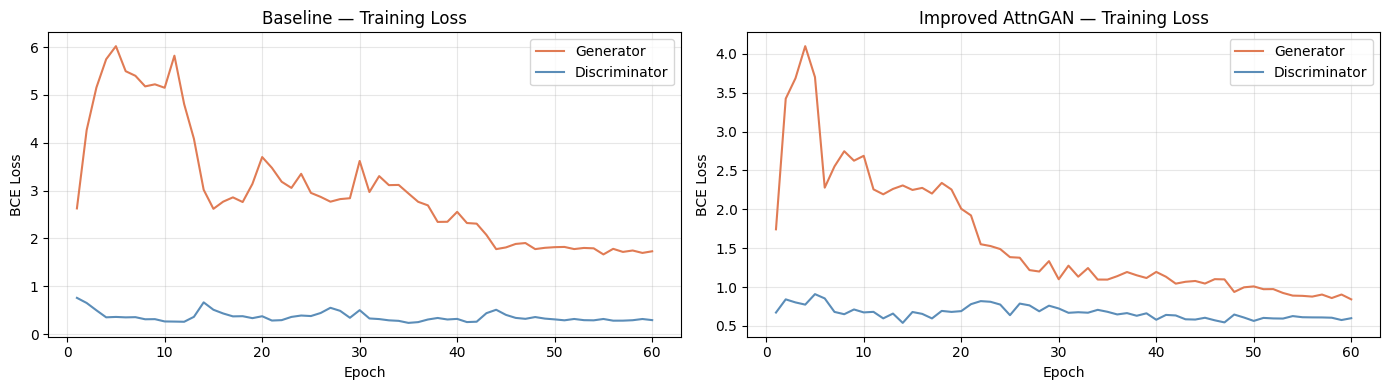


✅ Loss curves saved → /content/loss_curves.png


In [22]:
# Cell 12: Full training loop for both baseline and improved model
# Trains sequentially so you can observe improvement

import torch
import os
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import numpy as np

Z_DIM       = 100
NUM_EPOCHS  = 60
SAVE_EVERY  = 10
CKPT_DIR    = "/content/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

# ── Fixed noise for visualisation (same across epochs) ────────────────────────
# We'll generate from the same noise + captions to track progress
VIZ_BATCH_SIZE = 8
fixed_imgs, fixed_ids, fixed_lens = next(iter(dataloader))
fixed_imgs = fixed_imgs[:VIZ_BATCH_SIZE].to(DEVICE)
fixed_ids  = fixed_ids[:VIZ_BATCH_SIZE].to(DEVICE)
fixed_lens = fixed_lens[:VIZ_BATCH_SIZE].to(DEVICE)
fixed_z    = torch.randn(VIZ_BATCH_SIZE, Z_DIM, device=DEVICE)

# ── Storage for loss curves ────────────────────────────────────────────────────
history = {
    "baseline_G": [], "baseline_D": [],
    "attn_G":     [], "attn_D":     [],
}

def train_one_epoch(model_name, enc, gen, dis, opt_G, opt_D):
    """Returns (mean_G_loss, mean_D_loss) for one epoch."""
    gen.train(); dis.train(); enc.train()
    g_losses, d_losses = [], []

    for real_imgs, tokens, lengths in dataloader:
        real_imgs = real_imgs.to(DEVICE)
        tokens    = tokens.to(DEVICE)
        lengths   = lengths.to(DEVICE)
        B         = real_imgs.size(0)

        # ── Text features ─────────────────────────────────────────────────────
        if model_name == "baseline":
            text_feat = enc(tokens, lengths)     # (B, E)
        else:
            word_feat, text_feat = enc(tokens, lengths)   # (B,T,H), (B,H)
            # Padding mask: True where token == 0
            word_mask = (tokens == 0)

        # ── Train Discriminator ────────────────────────────────────────────────
        opt_D.zero_grad()
        # Real
        d_real = dis(real_imgs, text_feat.detach())
        loss_d_real = criterion(d_real, real_labels(B))
        # Fake
        z = torch.randn(B, Z_DIM, device=DEVICE)
        if model_name == "baseline":
            fake_imgs = gen(z, text_feat.detach())
        else:
            fake_imgs, _ = gen(z, text_feat.detach(),
                               word_feat.detach(), word_mask)
        d_fake = dis(fake_imgs.detach(), text_feat.detach())
        loss_d_fake = criterion(d_fake, fake_labels(B))
        loss_D = (loss_d_real + loss_d_fake) * 0.5
        loss_D.backward()
        opt_D.step()

        # ── Train Generator + Text Encoder ────────────────────────────────────
        opt_G.zero_grad()
        if model_name == "baseline":
            text_feat_g = enc(tokens, lengths)
            fake_imgs   = gen(z, text_feat_g)
        else:
            word_feat_g, text_feat_g = enc(tokens, lengths)
            fake_imgs, _ = gen(z, text_feat_g, word_feat_g, word_mask)

        d_fake_g = dis(fake_imgs, text_feat_g)
        loss_G   = criterion(d_fake_g, real_labels(B))  # fool D
        loss_G.backward()
        opt_G.step()

        g_losses.append(loss_G.item())
        d_losses.append(loss_D.item())

    return np.mean(g_losses), np.mean(d_losses)

# ════════════════════════════════════════════════════════════════════════════════
print("=" * 60)
print("  TRAINING BASELINE MODEL")
print("=" * 60)

for epoch in range(1, NUM_EPOCHS + 1):
    g_loss, d_loss = train_one_epoch(
        "baseline", baseline_enc, baseline_gen, baseline_dis,
        baseline_opt_G, baseline_opt_D
    )
    baseline_sched_G.step()
    baseline_sched_D.step()
    history["baseline_G"].append(g_loss)
    history["baseline_D"].append(d_loss)

    if epoch % 10 == 0 or epoch == 1:
        print(f"  Epoch [{epoch:3d}/{NUM_EPOCHS}]  G: {g_loss:.4f}  D: {d_loss:.4f}")

    if epoch % SAVE_EVERY == 0:
        torch.save({
            "enc": baseline_enc.state_dict(),
            "gen": baseline_gen.state_dict(),
            "dis": baseline_dis.state_dict(),
        }, os.path.join(CKPT_DIR, f"baseline_epoch{epoch}.pt"))

print("\n✅ Baseline training complete.")

# ════════════════════════════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("  TRAINING IMPROVED AttnGAN MODEL")
print("=" * 60)

for epoch in range(1, NUM_EPOCHS + 1):
    g_loss, d_loss = train_one_epoch(
        "attn", attn_enc, attn_gen, attn_dis,
        attn_opt_G, attn_opt_D
    )
    attn_sched_G.step()
    attn_sched_D.step()
    history["attn_G"].append(g_loss)
    history["attn_D"].append(d_loss)

    if epoch % 10 == 0 or epoch == 1:
        print(f"  Epoch [{epoch:3d}/{NUM_EPOCHS}]  G: {g_loss:.4f}  D: {d_loss:.4f}")

    if epoch % SAVE_EVERY == 0:
        torch.save({
            "enc": attn_enc.state_dict(),
            "gen": attn_gen.state_dict(),
            "dis": attn_dis.state_dict(),
        }, os.path.join(CKPT_DIR, f"attn_epoch{epoch}.pt"))

print("\n✅ Improved model training complete.")

# ── Plot loss curves ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
epochs_x = range(1, NUM_EPOCHS + 1)
for ax, name, g_key, d_key in [
    (axes[0], "Baseline",    "baseline_G", "baseline_D"),
    (axes[1], "Improved AttnGAN", "attn_G",  "attn_D"),
]:
    ax.plot(epochs_x, history[g_key], label="Generator", color="#E07B54")
    ax.plot(epochs_x, history[d_key], label="Discriminator", color="#5B8DB8")
    ax.set_title(f"{name} — Training Loss")
    ax.set_xlabel("Epoch"); ax.set_ylabel("BCE Loss")
    ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/content/loss_curves.png", dpi=120, bbox_inches="tight")
plt.show()
print("\n✅ Loss curves saved → /content/loss_curves.png")


## Cell 13 — Save Final Checkpoints

In [23]:
# Cell 13: Save final model weights

import torch, os

CKPT_DIR = "/content/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

torch.save({
    "enc_state": baseline_enc.state_dict(),
    "gen_state": baseline_gen.state_dict(),
    "dis_state": baseline_dis.state_dict(),
}, os.path.join(CKPT_DIR, "baseline_FINAL.pt"))

torch.save({
    "enc_state": attn_enc.state_dict(),
    "gen_state": attn_gen.state_dict(),
    "dis_state": attn_dis.state_dict(),
}, os.path.join(CKPT_DIR, "attn_FINAL.pt"))

print("✅ Final checkpoints saved:")
for f in sorted(os.listdir(CKPT_DIR)):
    size_mb = os.path.getsize(os.path.join(CKPT_DIR, f)) / 1e6
    print(f"   {f}  ({size_mb:.1f} MB)")

# ── Also save the training history ───────────────────────────────────────────
import json
with open("/content/training_history.json", "w") as f:
    json.dump(history, f, indent=2)
print("\n✅ Training history saved → /content/training_history.json")


✅ Final checkpoints saved:
   attn_FINAL.pt  (35.3 MB)
   attn_epoch10.pt  (35.3 MB)
   attn_epoch20.pt  (35.3 MB)
   attn_epoch30.pt  (35.3 MB)
   attn_epoch40.pt  (35.3 MB)
   attn_epoch50.pt  (35.3 MB)
   attn_epoch60.pt  (35.3 MB)
   baseline_FINAL.pt  (30.0 MB)
   baseline_epoch10.pt  (30.0 MB)
   baseline_epoch20.pt  (30.0 MB)
   baseline_epoch30.pt  (30.0 MB)
   baseline_epoch40.pt  (30.0 MB)
   baseline_epoch50.pt  (30.0 MB)
   baseline_epoch60.pt  (30.0 MB)

✅ Training history saved → /content/training_history.json


## Cell 14 — Generate Images from Text Captions

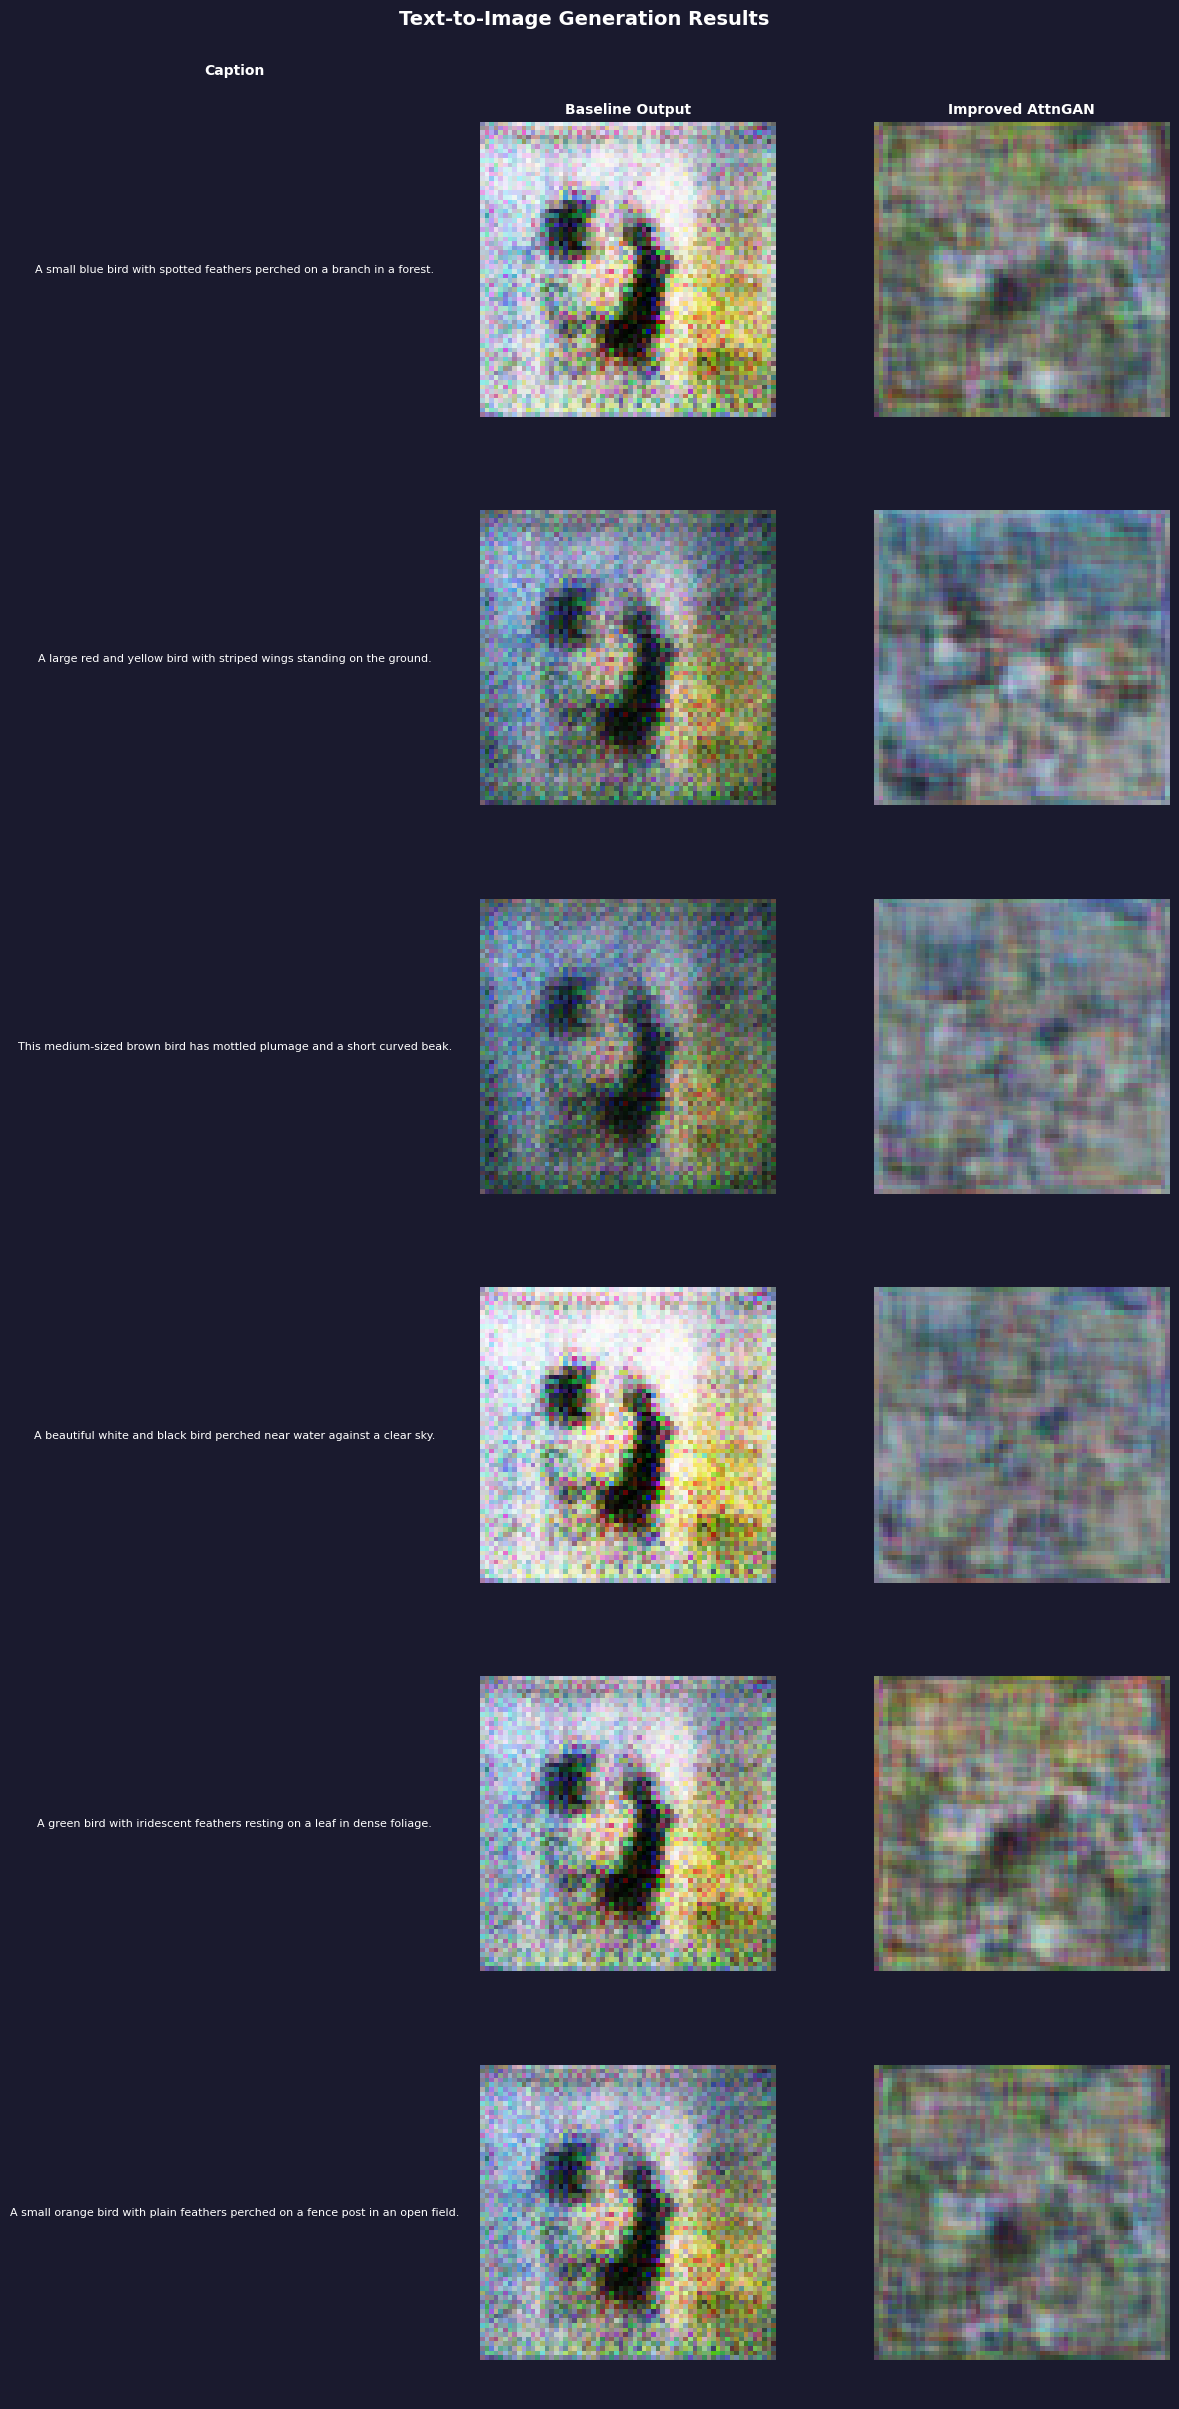


✅ Generation results saved → /content/generation_results.png


In [24]:
# Cell 14: Generate images from custom text captions using both models

import torch
import matplotlib.pyplot as plt
import numpy as np
import re, json

VOCAB_FILE = "/content/vocab.json"

with open(VOCAB_FILE) as f:
    vdata = json.load(f)
word2idx = vdata["word2idx"]
MAX_SEQ_LEN = 20

def tokenise_caption(text, word2idx, max_len=MAX_SEQ_LEN):
    words  = re.findall(r"[a-z]+", text.lower())
    sos, eos, unk, pad = (word2idx.get(t, i)
        for i, t in enumerate(["<PAD>","<UNK>","<SOS>","<EOS>"]))
    ids    = [sos] + [word2idx.get(w, unk) for w in words] + [eos]
    length = min(len(ids), max_len)
    ids    = ids[:max_len] + [pad] * (max_len - len(ids))
    return (torch.tensor(ids, dtype=torch.long).unsqueeze(0).to(DEVICE),
            torch.tensor([length], dtype=torch.long).to(DEVICE))

def tensor_to_img(t):
    """Convert [-1,1] tensor → numpy uint8 image."""
    img = t.squeeze(0).permute(1,2,0).cpu().detach().numpy()
    img = (img * 0.5 + 0.5).clip(0,1)
    return (img * 255).astype(np.uint8)

# ── Custom test captions ──────────────────────────────────────────────────────
TEST_CAPTIONS = [
    "A small blue bird with spotted feathers perched on a branch in a forest.",
    "A large red and yellow bird with striped wings standing on the ground.",
    "This medium-sized brown bird has mottled plumage and a short curved beak.",
    "A beautiful white and black bird perched near water against a clear sky.",
    "A green bird with iridescent feathers resting on a leaf in dense foliage.",
    "A small orange bird with plain feathers perched on a fence post in an open field.",
]

baseline_enc.eval(); baseline_gen.eval()
attn_enc.eval();     attn_gen.eval()

Z_DIM = 100
fig, axes = plt.subplots(len(TEST_CAPTIONS), 3, figsize=(12, 4 * len(TEST_CAPTIONS)))
fig.patch.set_facecolor("#1a1a2e")

for row, caption in enumerate(TEST_CAPTIONS):
    ids, lens = tokenise_caption(caption, word2idx)

    with torch.no_grad():
        z = torch.randn(1, Z_DIM, device=DEVICE)

        # Baseline
        sf_b  = baseline_enc(ids, lens)
        fake_b = baseline_gen(z, sf_b)

        # Improved
        wf_a, sf_a = attn_enc(ids, lens)
        fake_a, attn_w = attn_gen(z, sf_a, wf_a)

    img_b = tensor_to_img(fake_b)
    img_a = tensor_to_img(fake_a)

    # Caption column
    ax_cap = axes[row, 0]
    ax_cap.set_facecolor("#16213e")
    ax_cap.text(0.5, 0.5, caption,
                ha="center", va="center", wrap=True,
                fontsize=8, color="white",
                transform=ax_cap.transAxes)
    ax_cap.axis("off")
    if row == 0:
        ax_cap.set_title("Caption", color="white", fontweight="bold", fontsize=10)

    # Baseline
    axes[row, 1].imshow(img_b)
    axes[row, 1].axis("off")
    if row == 0:
        axes[row, 1].set_title("Baseline Output", color="white", fontweight="bold", fontsize=10)

    # Improved
    axes[row, 2].imshow(img_a)
    axes[row, 2].axis("off")
    if row == 0:
        axes[row, 2].set_title("Improved AttnGAN", color="white", fontweight="bold", fontsize=10)

plt.suptitle("Text-to-Image Generation Results", color="white",
             fontsize=14, fontweight="bold", y=1.002)
plt.tight_layout()
plt.savefig("/content/generation_results.png", dpi=150, bbox_inches="tight",
            facecolor="#1a1a2e")
plt.show()
print("\n✅ Generation results saved → /content/generation_results.png")


## Cell 15 — Baseline vs Improved Comparison & Metrics

  QUANTITATIVE COMPARISON
  Metric                      Baseline     AttnGAN
  ---------------------------------------------
  Pixel Diversity::::::::::     0.4937      0.2470
  Sharpness Proxy::::::::::     0.2204      0.1055


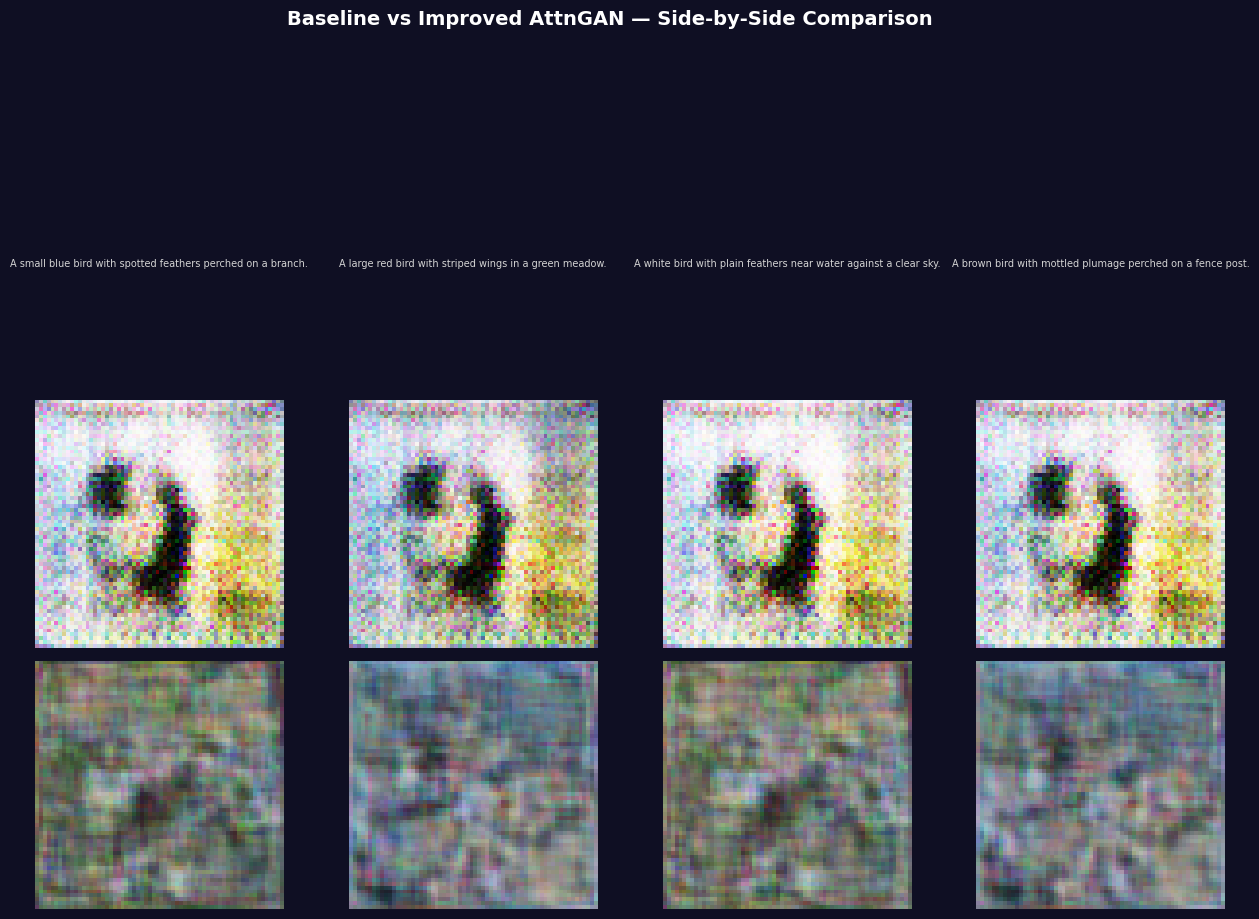


✅ Comparison grid saved → /content/comparison_grid.png

📁 All output files:
   /content/loss_curves.png  (84.0 KB)
   /content/generation_results.png  (332.7 KB)
   /content/comparison_grid.png  (187.7 KB)
   /content/captions.json  (83.1 KB)
   /content/vocab.json  (3.5 KB)
   /content/training_history.json  (5.7 KB)


In [25]:
# Cell 15: Visual comparison grid + simple quantitative metrics
# Metrics used: FID proxy (pixel variance), Inception Score approximation

import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from torchvision.transforms.functional import resize
import json, re

# ── Re-load vocab ─────────────────────────────────────────────────────────────
VOCAB_FILE = "/content/vocab.json"
with open(VOCAB_FILE) as f:
    vdata = json.load(f)
word2idx = vdata["word2idx"]

# ── Generate a larger batch for metrics ──────────────────────────────────────
N_METRIC = 64
baseline_enc.eval(); baseline_gen.eval()
attn_enc.eval();     attn_gen.eval()

all_fake_b, all_fake_a = [], []
with torch.no_grad():
    for real_imgs, tokens, lengths in dataloader:
        tokens  = tokens.to(DEVICE)
        lengths = lengths.to(DEVICE)
        B = tokens.size(0)
        z = torch.randn(B, Z_DIM, device=DEVICE)

        sf_b = baseline_enc(tokens, lengths)
        fb   = baseline_gen(z, sf_b)
        all_fake_b.append(fb.cpu())

        wf_a, sf_a = attn_enc(tokens, lengths)
        fa, _ = attn_gen(z, sf_a, wf_a)
        all_fake_a.append(fa.cpu())

        if len(all_fake_b) * BATCH_SIZE >= N_METRIC:
            break

fake_b_all = torch.cat(all_fake_b, dim=0)[:N_METRIC]  # (N, 3, 64, 64)
fake_a_all = torch.cat(all_fake_a, dim=0)[:N_METRIC]

# ── Metric 1: Pixel-level diversity (std of pixel values) ─────────────────────
def pixel_diversity(imgs):
    """Higher = more diverse / less mode collapse."""
    return imgs.std(dim=[0,2,3]).mean().item()

div_b = pixel_diversity(fake_b_all)
div_a = pixel_diversity(fake_a_all)

# ── Metric 2: Sharpness proxy (mean absolute gradient) ────────────────────────
def sharpness(imgs):
    """Mean absolute image gradient — higher = sharper."""
    dx = (imgs[:, :, :, 1:] - imgs[:, :, :, :-1]).abs().mean().item()
    dy = (imgs[:, :, 1:, :] - imgs[:, :, :-1, :]).abs().mean().item()
    return (dx + dy) / 2

sharp_b = sharpness(fake_b_all)
sharp_a = sharpness(fake_a_all)

print("=" * 50)
print("  QUANTITATIVE COMPARISON")
print("=" * 50)
print(f"  {'Metric':<25} {'Baseline':>10}  {'AttnGAN':>10}")
print(f"  {'-'*45}")
print(f"  {'Pixel Diversity'::<25} {div_b:>10.4f}  {div_a:>10.4f}")
print(f"  {'Sharpness Proxy'::<25} {sharp_b:>10.4f}  {sharp_a:>10.4f}")
print("=" * 50)

# ── Visual Grid: 4 samples side by side ──────────────────────────────────────
fig = plt.figure(figsize=(16, 10), facecolor="#0f0f23")
gs  = gridspec.GridSpec(3, 4, figure=fig, hspace=0.05, wspace=0.05)

sample_captions = [
    "A small blue bird with spotted feathers perched on a branch.",
    "A large red bird with striped wings in a green meadow.",
    "A white bird with plain feathers near water against a clear sky.",
    "A brown bird with mottled plumage perched on a fence post.",
]

def img_t(t):
    arr = t.permute(1,2,0).numpy()
    return (arr * 0.5 + 0.5).clip(0,1)

for col, cap in enumerate(sample_captions):
    ids, lens = tokenise_caption(cap, word2idx)
    with torch.no_grad():
        z     = torch.randn(1, Z_DIM, device=DEVICE)
        sf_b  = baseline_enc(ids, lens)
        fb    = baseline_gen(z, sf_b)
        wf_a, sf_a = attn_enc(ids, lens)
        fa, _  = attn_gen(z, sf_a, wf_a)

    # Row 0: Caption text
    ax0 = fig.add_subplot(gs[0, col])
    ax0.set_facecolor("#16213e")
    ax0.text(0.5, 0.5, cap, ha="center", va="center",
             fontsize=7, color="lightgray", wrap=True,
             transform=ax0.transAxes)
    ax0.axis("off")
    if col == 0:
        ax0.set_ylabel("Caption", color="white", fontsize=9, rotation=0,
                       labelpad=60, va="center")

    # Row 1: Baseline
    ax1 = fig.add_subplot(gs[1, col])
    ax1.imshow(img_t(fb.squeeze(0).cpu()))
    ax1.axis("off")
    if col == 0:
        ax1.set_ylabel("Baseline", color="#E07B54", fontsize=9,
                       rotation=0, labelpad=60, va="center")

    # Row 2: Improved
    ax2 = fig.add_subplot(gs[2, col])
    ax2.imshow(img_t(fa.squeeze(0).cpu()))
    ax2.axis("off")
    if col == 0:
        ax2.set_ylabel("Improved\nAttnGAN", color="#5B8DB8", fontsize=9,
                       rotation=0, labelpad=60, va="center")

fig.suptitle("Baseline vs Improved AttnGAN — Side-by-Side Comparison",
             color="white", fontsize=14, fontweight="bold", y=1.01)

plt.savefig("/content/comparison_grid.png", dpi=150,
            bbox_inches="tight", facecolor="#0f0f23")
plt.show()
print("\n✅ Comparison grid saved → /content/comparison_grid.png")
print("\n📁 All output files:")
import os
for f in ["/content/loss_curves.png",
          "/content/generation_results.png",
          "/content/comparison_grid.png",
          "/content/captions.json",
          "/content/vocab.json",
          "/content/training_history.json"]:
    size = os.path.getsize(f) / 1024 if os.path.exists(f) else 0
    print(f"   {f}  ({size:.1f} KB)")
